In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [3]:
def preprocess_for_ml(df):
    """
    Cleans raw REFIT data, sorts chronologically, and generates time-series features.
    """
    # 0. Set time as index (if it isn't already) and sort chronologically
    if 'Time' in df.columns:
        df = df.set_index('Time')
    elif not pd.api.types.is_datetime64_any_dtype(df.index):
        print("Error: DataFrame must have a 'Time' column or a DatetimeIndex.")
        return
    
    df.index = pd.to_datetime(df.index)
    df = df.sort_index()
    
    # 1. Basic Cleanup & 1-Minute Resolution
    df = df[~df.index.duplicated(keep='first')]
    df = df.resample('1min').mean()
    
    # 2. Feature Engineering: Lags & Leads (Capturing the spike shape)
    df['Agg_Lag1'] = df['Aggregate'].shift(1)
    df['Agg_Lag2'] = df['Aggregate'].shift(2)
    df['Agg_Lead1'] = df['Aggregate'].shift(-1)
    df['Agg_Lead2'] = df['Aggregate'].shift(-2)
    
    # 3. Feature Engineering: Rolling Statistics (Smoothing noise)
    # center=True allows the model to look slightly forward and backward in the window
    df['Agg_Roll_Mean_15'] = df['Aggregate'].rolling(window=15, center=True).mean()
    df['Agg_Roll_Std_15'] = df['Aggregate'].rolling(window=15, center=True).std()
    
    # 4. Feature Engineering: Temporal Context
    df['Hour'] = df.index.hour
    df['DayOfWeek'] = df.index.dayofweek
    
    # 5. Handle Null Values
    # Machine learning models (like Random Forest) cannot process NaNs.
    columns_to_check = ['Aggregate', 'Washing_Machine', 'Agg_Lag2', 'Agg_Lead2', 'Agg_Roll_Std_15']
    df_clean = df.dropna(subset=columns_to_check)
    
    # 6. Separate Features (X) and Target (y)
    features = ['Aggregate', 'Agg_Lag1', 'Agg_Lag2', 'Agg_Lead1', 'Agg_Lead2', 
                'Agg_Roll_Mean_15', 'Agg_Roll_Std_15', 'Hour', 'DayOfWeek']
    
    X = df_clean[features]
    y = df_clean['Washing_Machine']
    
    return X, y, df_clean.index

In [4]:
def split_chronological(X, y, train_ratio=0.8):
    """
    Splits time-series data chronologically to prevent data leakage.
    """
    split_idx = int(len(X) * train_ratio)
    
    X_train = X.iloc[:split_idx]
    X_test = X.iloc[split_idx:]
    
    y_train = y.iloc[:split_idx]
    y_test = y.iloc[split_idx:]
    
    return X_train, X_test, y_train, y_test

In [14]:
washing_machine_map = {
    'House1': 'Appliance5',
    'House2': 'Appliance2',
    'House3': 'Appliance6',
    'House5': 'Appliance3',
    'House6': 'Appliance2',
    'House7': 'Appliance5',
    'House10': 'Appliance5',
    'House11': 'Appliance3',
    'House13': 'Appliance3',
    'House15': 'Appliance3',
    'House16': 'Appliance5',
    'House17': 'Appliance4',
    'House19': 'Appliance2',
    'House20': 'Appliance4',
    'House21': 'Appliance3'
}

In [15]:
def load_and_format_data(file_path, house_name):
    """Loads the CSV, filters to the 3 required columns, and standardizes names."""
    print(f"Loading {file_path}...")
    df = pd.read_csv(file_path)
    
    # Identify the correct column for this specific house
    wm_col = washing_machine_map.get(house_name)
    if not wm_col:
        raise ValueError(f"No valid washing machine mapping found for {house_name}")
    
    # Keep only the 3 strictly necessary columns to save memory
    df = df[['Time', 'Aggregate', wm_col]]
    
    # Rename the appliance column to our standard target variable name
    df = df.rename(columns={wm_col: 'Washing_Machine'})
    
    return df

In [ ]:
from sklearn.ensemble import RandomForestRegressor, HistGradientBoostingRegressor
from sklearn.tree import DecisionTreeRegressor
from sklearn.linear_model import Ridge
from sklearn.metrics import mean_absolute_error, f1_score
import numpy as np

def evaluate_multiple_models(df, power_threshold=50):
    """
    Preprocesses data once, then tests multiple models to find the best performer.
    """
    print("Preprocessing data and engineering features...")
    X, y, _ = preprocess_for_ml(df)
    
    print("Splitting data chronologically (80/20)...")
    X_train, X_test, y_train, y_test = split_chronological(X, y, train_ratio=0.8)
    
    # Establish Baseline
    baseline_predictions = np.zeros(len(y_test))
    baseline_mae = mean_absolute_error(y_test, baseline_predictions)
    y_test_binary = (y_test > power_threshold).astype(int)
    baseline_f1 = f1_score(y_test_binary, np.zeros(len(y_test)))
    
    print(f"\n--- BASELINE (Always Off) ---")
    print(f"MAE: {baseline_mae:.2f} W | F1: {baseline_f1:.4f}\n")

    # Define the models to compete
    models = {
        "Random Forest": RandomForestRegressor(n_estimators=50, max_depth=10, random_state=42, n_jobs=-1),
        "Gradient Boosting": HistGradientBoostingRegressor(max_iter=100, random_state=42),
        "Decision Tree": DecisionTreeRegressor(max_depth=10, random_state=42),
        "Ridge (Linear)": Ridge(alpha=1.0)
    }
    
    best_f1 = -1
    best_model_name = ""
    model_results = {}
    
    for name, model in models.items():
        print(f"Training {name}...")
        model.fit(X_train, y_train)
        
        preds = model.predict(X_test)
        
        mae = mean_absolute_error(y_test, preds)
        preds_binary = (preds > power_threshold).astype(int)
        f1 = f1_score(y_test_binary, preds_binary)
        
        print(f"{name} -> MAE: {mae:.2f} W | F1: {f1:.4f}")
        
        model_results[name] = {'MAE': mae, 'F1': f1, 'Model': model, 'Predictions': preds}
        
        if f1 > best_f1:
            best_f1 = f1
            best_model_name = name
            
    print(f"\n🏆 Best Model: {best_model_name} with F1-Score: {best_f1:.4f}")
    
    return model_results, y_test

In [22]:
from sklearn.ensemble import RandomForestRegressor, HistGradientBoostingRegressor, ExtraTreesRegressor
from sklearn.tree import DecisionTreeRegressor
from sklearn.linear_model import Ridge
from sklearn.neural_network import MLPRegressor
from sklearn.neighbors import KNeighborsRegressor
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import mean_absolute_error, f1_score
import numpy as np

def evaluate_extended_models(df, power_threshold=50):
    """
    Tests an extended suite of models including Neural Networks and KNN.
    """
    print("Preprocessing data and engineering features...")
    X, y, _ = preprocess_for_ml(df)
    
    print("Splitting data chronologically (80/20)...")
    X_train, X_test, y_train, y_test = split_chronological(X, y, train_ratio=0.8)
    
    # Scale data for Neural Network and KNN
    scaler = StandardScaler()
    X_train_scaled = scaler.fit_transform(X_train)
    X_test_scaled = scaler.transform(X_test)
    
    y_test_binary = (y_test > power_threshold).astype(int)
    
    # Define the models
    models = {
        "Decision Tree": (DecisionTreeRegressor(max_depth=10, random_state=42), False),
        "Extra Trees": (ExtraTreesRegressor(n_estimators=50, max_depth=15, random_state=42, n_jobs=-1), False),
        "K-Nearest Neighbors": (KNeighborsRegressor(n_neighbors=5, n_jobs=-1), True)
    }
    
    best_f1 = -1
    best_model_name = ""
    model_results = {}
    
    print("\n--- Training Extended Models ---")
    for name, (model, requires_scaling) in models.items():
        print(f"Training {name}...")
        
        # Use scaled data if the model requires it
        train_features = X_train_scaled if requires_scaling else X_train
        test_features = X_test_scaled if requires_scaling else X_test
        
        model.fit(train_features, y_train)
        preds = model.predict(test_features)
        
        mae = mean_absolute_error(y_test, preds)
        preds_binary = (preds > power_threshold).astype(int)
        f1 = f1_score(y_test_binary, preds_binary)
        
        print(f"{name} -> MAE: {mae:.2f} W | F1: {f1:.4f}")
        
        model_results[name] = {'MAE': mae, 'F1': f1, 'Model': model, 'Predictions': preds}
        
        if f1 > best_f1:
            best_f1 = f1
            best_model_name = name
            
    print(f"\n🏆 Best Model: {best_model_name} with F1-Score: {best_f1:.4f}")
    
    return model_results, y_test


In [23]:
import os
base_path = r"D:\Assessment\Flock Energy Assessment\cleaned_dataset"
houses_to_test = ['House1', 'House2', 'House3', 'House5']  
all_house_results = {}

for house_name in houses_to_test:
    print(f"\n========== Processing {house_name} ==========")
    
    # Construct the exact file path
    file_path = os.path.join(base_path, f"CLEAN_{house_name}.csv")
    
    try:
        # Load and format
        df_raw = load_and_format_data(file_path, house_name)
        
        # Pass to the full ML pipeline
        results = evaluate_multiple_models(df_raw, power_threshold=50)
        results = evaluate_extended_models(df_raw, power_threshold=50)
        
        # Store results
        all_house_results[house_name] = results
        
    except FileNotFoundError:
        print(f"Error: Could not find the dataset at {file_path}")
    except Exception as e:
        print(f"Failed to process {house_name}: {e}")


========== Processing House1 ==========
Loading D:\Assessment\Flock Energy Assessment\cleaned_dataset\CLEAN_House1.csv...
Preprocessing data and engineering features...


C:\Users\Aditya Raj\AppData\Local\Temp\ipykernel_15312\2702227860.py:32: Pandas4Warning: DatetimeIndex.dayofweek is deprecated and will be removed in a future version. Use DatetimeIndex.day_of_week instead.
  df['DayOfWeek'] = df.index.dayofweek


Splitting data chronologically (80/20)...

--- BASELINE (Always Off) ---
MAE: 10.63 W | F1: 0.0000

Training Random Forest...
Random Forest -> MAE: 11.53 W | F1: 0.4137
Training Gradient Boosting...
Gradient Boosting -> MAE: 11.29 W | F1: 0.4118
Training Decision Tree...
Decision Tree -> MAE: 11.47 W | F1: 0.4227
Training Ridge (Linear)...
Ridge (Linear) -> MAE: 22.88 W | F1: 0.1144

🏆 Best Model: Decision Tree with F1-Score: 0.4227
Preprocessing data and engineering features...


C:\Users\Aditya Raj\AppData\Local\Temp\ipykernel_15312\2702227860.py:32: Pandas4Warning: DatetimeIndex.dayofweek is deprecated and will be removed in a future version. Use DatetimeIndex.day_of_week instead.
  df['DayOfWeek'] = df.index.dayofweek


Splitting data chronologically (80/20)...

--- Training Extended Models ---
Training Decision Tree...
Decision Tree -> MAE: 11.47 W | F1: 0.4227
Training Extra Trees...
Extra Trees -> MAE: 12.44 W | F1: 0.4286
Training K-Nearest Neighbors...
K-Nearest Neighbors -> MAE: 9.90 W | F1: 0.4675

🏆 Best Model: K-Nearest Neighbors with F1-Score: 0.4675

========== Processing House2 ==========
Loading D:\Assessment\Flock Energy Assessment\cleaned_dataset\CLEAN_House2.csv...
Preprocessing data and engineering features...


C:\Users\Aditya Raj\AppData\Local\Temp\ipykernel_15312\2702227860.py:32: Pandas4Warning: DatetimeIndex.dayofweek is deprecated and will be removed in a future version. Use DatetimeIndex.day_of_week instead.
  df['DayOfWeek'] = df.index.dayofweek


... (7 outputs left out)

C:\Users\Aditya Raj\AppData\Local\Temp\ipykernel_15312\2702227860.py:32: Pandas4Warning: DatetimeIndex.dayofweek is deprecated and will be removed in a future version. Use DatetimeIndex.day_of_week instead.
  df['DayOfWeek'] = df.index.dayofweek


Splitting data chronologically (80/20)...

--- BASELINE (Always Off) ---
MAE: 40.02 W | F1: 0.0000

Training Random Forest...
Random Forest -> MAE: 47.86 W | F1: 0.3441
Training Gradient Boosting...
Gradient Boosting -> MAE: 50.39 W | F1: 0.3089
Training Decision Tree...
Decision Tree -> MAE: 47.94 W | F1: 0.3103
Training Ridge (Linear)...
Ridge (Linear) -> MAE: 58.67 W | F1: 0.3096

🏆 Best Model: Random Forest with F1-Score: 0.3441
Preprocessing data and engineering features...


C:\Users\Aditya Raj\AppData\Local\Temp\ipykernel_15312\2702227860.py:32: Pandas4Warning: DatetimeIndex.dayofweek is deprecated and will be removed in a future version. Use DatetimeIndex.day_of_week instead.
  df['DayOfWeek'] = df.index.dayofweek


Splitting data chronologically (80/20)...

--- Training Extended Models ---
Training Decision Tree...
Decision Tree -> MAE: 47.94 W | F1: 0.3103
Training Extra Trees...
Extra Trees -> MAE: 49.14 W | F1: 0.3597
Training K-Nearest Neighbors...
K-Nearest Neighbors -> MAE: 48.44 W | F1: 0.3040

🏆 Best Model: Extra Trees with F1-Score: 0.3597


In [24]:
from sklearn.ensemble import ExtraTreesRegressor
from sklearn.metrics import mean_absolute_error, f1_score
import numpy as np

def train_and_evaluate_pipeline(df, power_threshold=50):
    """
    Runs the full end-to-end ML pipeline on a single household's dataframe.
    """
    # 1. Preprocess
    print("Preprocessing data and engineering features...")
    X, y, _ = preprocess_for_ml(df)
    
    # 2. Chronological Split
    print("Splitting data chronologically (80/20)...")
    X_train, X_test, y_train, y_test = split_chronological(X, y, train_ratio=0.8)
    
    # 3. Establish Baseline (Always-Off)
    baseline_predictions = np.zeros(len(y_test))
    baseline_mae = mean_absolute_error(y_test, baseline_predictions)
    
    # 4. Train the ML Model
    print("Training Extra Trees model...")
    model = ExtraTreesRegressor(n_estimators=50, max_depth=15, random_state=42, n_jobs=-1)
    model.fit(X_train, y_train)
    
    # 5. Predict on Holdout Set
    print("Generating predictions...")
    ml_predictions = model.predict(X_test)
    
    # 6. Evaluate Metrics
    ml_mae = mean_absolute_error(y_test, ml_predictions)
    
    # Threshold predictions to binary ON/OFF for Classification Metrics
    y_test_binary = (y_test >= power_threshold).astype(int)
    ml_predictions_binary = (ml_predictions >= power_threshold).astype(int)
    baseline_binary = np.zeros(len(y_test))
    
    ml_f1 = f1_score(y_test_binary, ml_predictions_binary)
    baseline_f1 = f1_score(y_test_binary, baseline_binary)
    
    # Package all necessary components into a dictionary
    results = {
        'Baseline_MAE': baseline_mae,
        'Baseline_F1': baseline_f1,
        'Model_MAE': ml_mae,
        'Model_F1': ml_f1,
        'Model': model,
        'X_test': X_test,  
        'y_test': y_test,
        'Predictions': ml_predictions
    }
    
    print(f"Pipeline Complete!")
    print(f"Baseline -> MAE: {baseline_mae:.2f} W | F1: {baseline_f1:.4f}")
    print(f"Model    -> MAE: {ml_mae:.2f} W | F1: {ml_f1:.4f}\n")
    
    return results

In [ ]:
import os
base_path = r"D:\Assessment\Flock Energy Assessment\cleaned_dataset"
houses_to_test = ['House1', 'House2', 'House3', 'House5']  
all_house_results = {}

for house_name in houses_to_test:
    print(f"\n========== Processing {house_name} ==========")
    
    # Construct the exact file path
    file_path = os.path.join(base_path, f"CLEAN_{house_name}.csv")
    
    try:
        # Load and format
        df_raw = load_and_format_data(file_path, house_name)
        
        # Pass to the full ML pipeline
        results = train_and_evaluate_pipeline(df_raw, power_threshold=50)
        
        # Store results
        all_house_results[house_name] = results
        
    except FileNotFoundError:
        print(f"Error: Could not find the dataset at {file_path}")
    except Exception as e:
        print(f"Failed to process {house_name}: {e}")


========== Processing House1 ==========
Loading D:\Assessment\Flock Energy Assessment\cleaned_dataset\CLEAN_House1.csv...
Preprocessing data and engineering features...


C:\Users\Aditya Raj\AppData\Local\Temp\ipykernel_15312\2702227860.py:32: Pandas4Warning: DatetimeIndex.dayofweek is deprecated and will be removed in a future version. Use DatetimeIndex.day_of_week instead.
  df['DayOfWeek'] = df.index.dayofweek


Splitting data chronologically (80/20)...
Training Extra Trees model...
Generating predictions...
Pipeline Complete!
Baseline -> MAE: 10.63 W | F1: 0.0000
Model    -> MAE: 12.44 W | F1: 0.4286


========== Processing House2 ==========
Loading D:\Assessment\Flock Energy Assessment\cleaned_dataset\CLEAN_House2.csv...
Preprocessing data and engineering features...


C:\Users\Aditya Raj\AppData\Local\Temp\ipykernel_15312\2702227860.py:32: Pandas4Warning: DatetimeIndex.dayofweek is deprecated and will be removed in a future version. Use DatetimeIndex.day_of_week instead.
  df['DayOfWeek'] = df.index.dayofweek


Splitting data chronologically (80/20)...
Training Extra Trees model...
Generating predictions...
Pipeline Complete!
Baseline -> MAE: 20.14 W | F1: 0.0000
Model    -> MAE: 39.32 W | F1: 0.2821


========== Processing House3 ==========
Loading D:\Assessment\Flock Energy Assessment\cleaned_dataset\CLEAN_House3.csv...
Preprocessing data and engineering features...


C:\Users\Aditya Raj\AppData\Local\Temp\ipykernel_15312\2702227860.py:32: Pandas4Warning: DatetimeIndex.dayofweek is deprecated and will be removed in a future version. Use DatetimeIndex.day_of_week instead.
  df['DayOfWeek'] = df.index.dayofweek


Splitting data chronologically (80/20)...
Training Extra Trees model...
Generating predictions...
Pipeline Complete!
Baseline -> MAE: 30.15 W | F1: 0.0000
Model    -> MAE: 41.47 W | F1: 0.4007


========== Processing House5 ==========
Loading D:\Assessment\Flock Energy Assessment\cleaned_dataset\CLEAN_House5.csv...
Preprocessing data and engineering features...


C:\Users\Aditya Raj\AppData\Local\Temp\ipykernel_15312\2702227860.py:32: Pandas4Warning: DatetimeIndex.dayofweek is deprecated and will be removed in a future version. Use DatetimeIndex.day_of_week instead.
  df['DayOfWeek'] = df.index.dayofweek


Splitting data chronologically (80/20)...
Training Extra Trees model...
Generating predictions...
Pipeline Complete!
Baseline -> MAE: 40.02 W | F1: 0.0000
Model    -> MAE: 49.14 W | F1: 0.3597



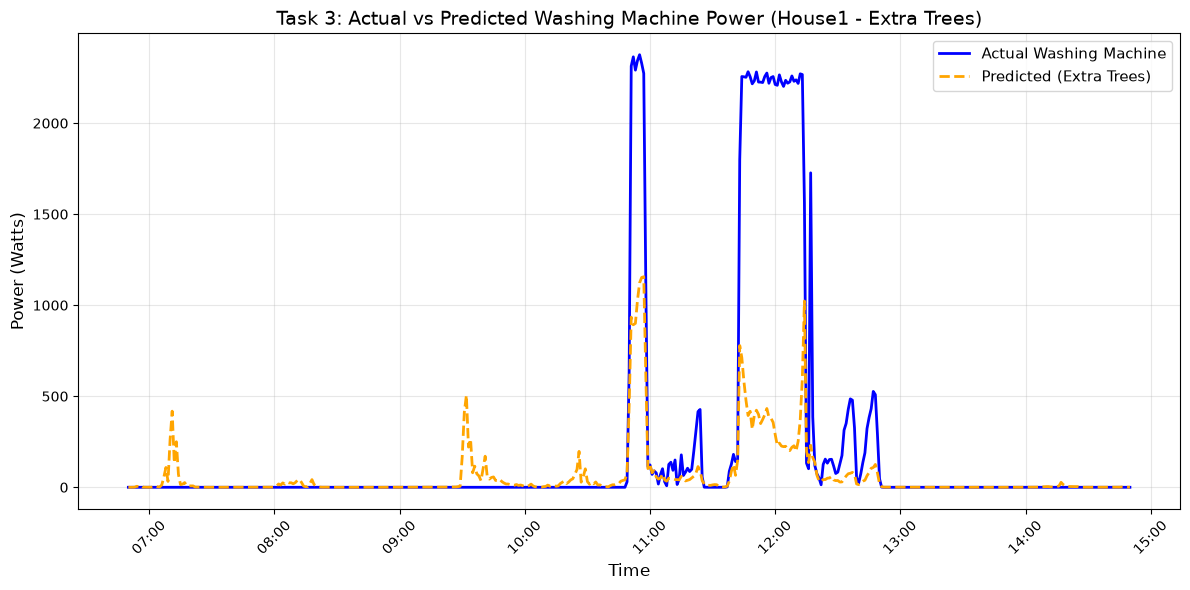

Plot saved successfully as 'D:\Assessment\Flock Energy Assessment\images\Task3_Actual_vs_Predicted_House1.png'


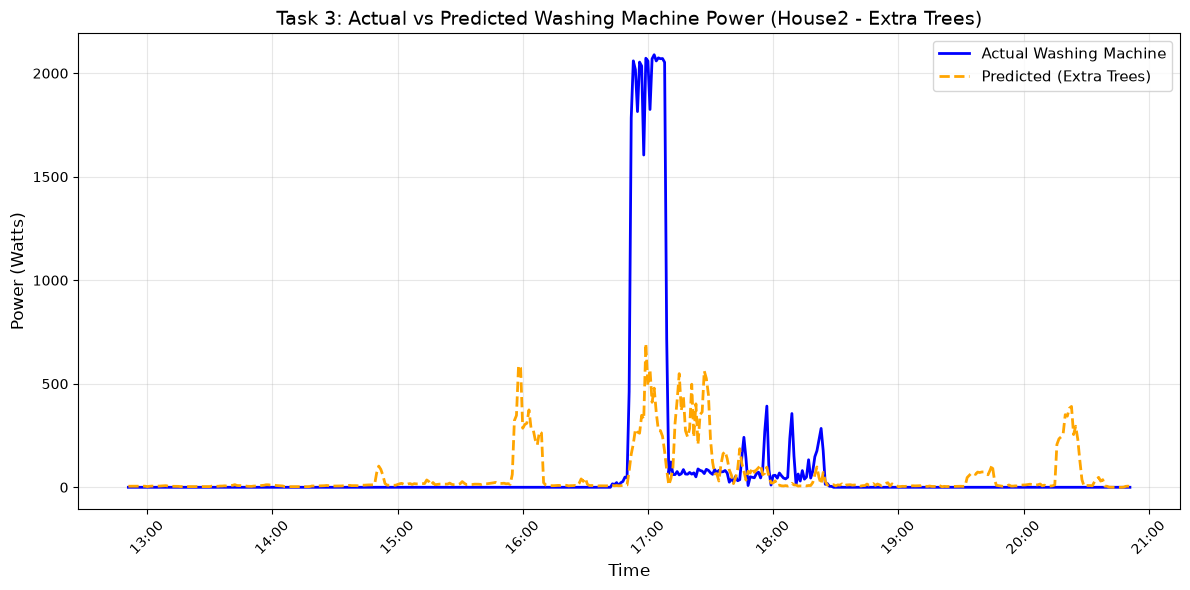

Plot saved successfully as 'D:\Assessment\Flock Energy Assessment\images\Task3_Actual_vs_Predicted_House2.png'


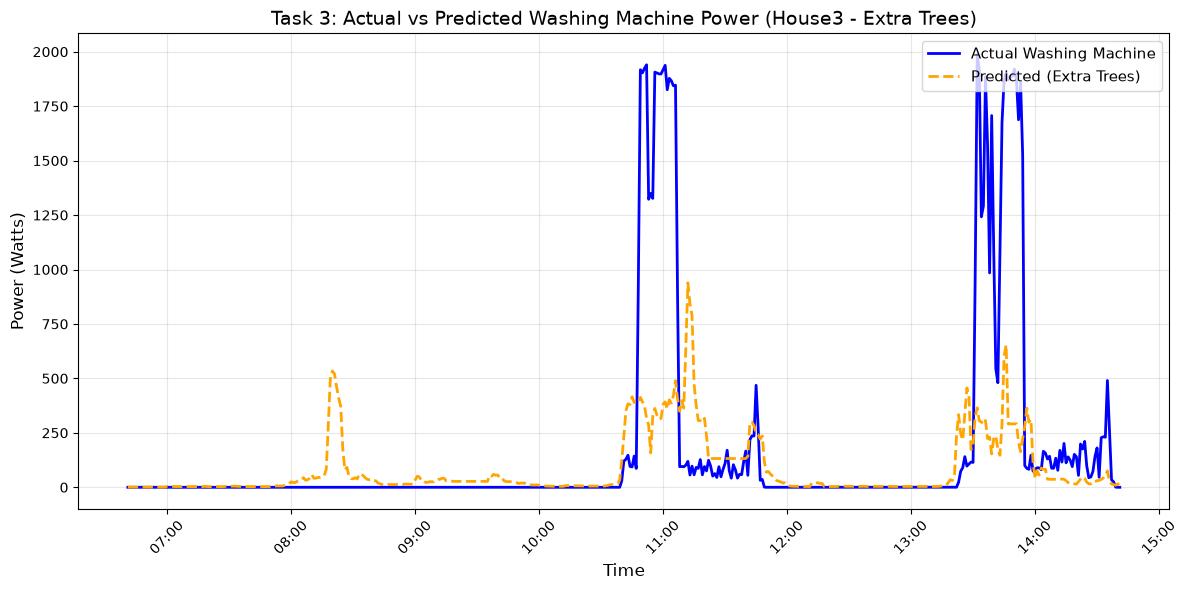

Plot saved successfully as 'D:\Assessment\Flock Energy Assessment\images\Task3_Actual_vs_Predicted_House3.png'


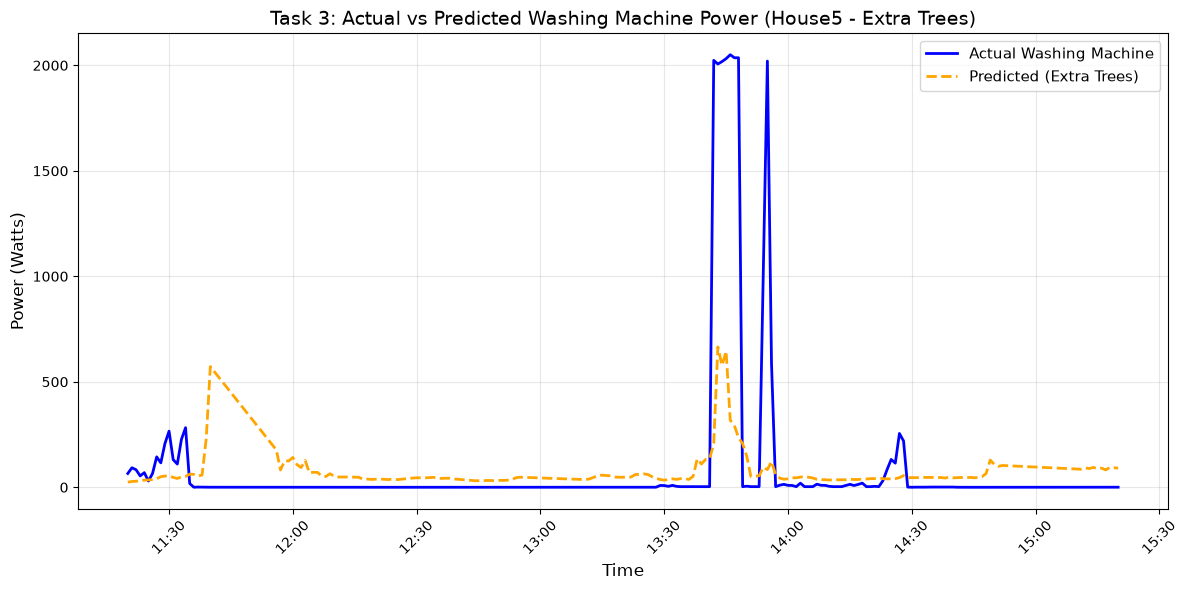

Plot saved successfully as 'D:\Assessment\Flock Energy Assessment\images\Task3_Actual_vs_Predicted_House5.png'


In [30]:
import matplotlib.dates as mdates

for house_name in houses_to_test:
    results = all_house_results[house_name]
    
    # 1. Extract test data and predictions
    y_test = results['y_test']
    predictions = results['Predictions']
    pred_series = pd.Series(predictions, index=y_test.index)

    # 2. Find timestamps where the washing machine was actually ON (>50W)
    on_times = y_test[y_test > 50].index
    
    # Everything related to plotting must be indented INSIDE this if statement
    if not on_times.empty:
        # 3. Pick the first detected cycle in the holdout test set
        target_cycle_time = on_times[0]
        
        # 4. Create an 8-hour viewing window (4 hours before, 4 hours after)
        start_time = target_cycle_time - pd.Timedelta(hours=4)
        end_time = target_cycle_time + pd.Timedelta(hours=4)
        
        y_test_slice = y_test[start_time:end_time]
        pred_slice = pred_series[start_time:end_time]
        
        # 5. Generate the clear actual-vs-predicted plot
        fig, ax = plt.subplots(figsize=(12, 6))
        
        ax.plot(y_test_slice.index, y_test_slice.values, 
                label='Actual Washing Machine', color='blue', linewidth=2)
        ax.plot(pred_slice.index, pred_slice.values, 
                label='Predicted (Extra Trees)', color='orange', linestyle='--', linewidth=2)
        
        # Fixed: Made the title dynamic so it shows the correct house name
        ax.set_title(f'Task 3: Actual vs Predicted Washing Machine Power ({house_name} - Extra Trees)', fontsize=14)
        ax.set_ylabel('Power (Watts)', fontsize=12)
        ax.set_xlabel('Time', fontsize=12)
        
        # Format x-axis to show clear times
        ax.xaxis.set_major_formatter(mdates.DateFormatter('%H:%M'))
        plt.xticks(rotation=45)
        
        ax.legend(loc='upper right', fontsize=11)
        ax.grid(True, alpha=0.3)
        plt.tight_layout()
        
        # Fixed: Made the filename dynamic so it doesn't overwrite the same image in the loop
        filename = rf'D:\Assessment\Flock Energy Assessment\images\Task3_Actual_vs_Predicted_{house_name}.png'
        plt.savefig(filename, dpi=300)
        plt.show()
        print(f"Plot saved successfully as '{filename}'")
        
    # The else statement must align with the 'if', still inside the 'for' loop
    else:
        print(f"No active cycles found in the test set to plot for {house_name}.")